# Module 2 — Neural Networks

Classificazione del **Severity Impairment Index (`sii`)** sul dataset CMI con reti neurali.

Il preprocessing (split, scaling, encoding) è **identico** a quello del notebook di Logistic Regression,
così i risultati dei diversi classificatori del Modulo 2 sono confrontabili sullo stesso test set.

**Struttura**
1. Setup
2. Caricamento dati e preprocessing (comune al Modulo 2)
3. Funzioni di valutazione
4. Baseline: Dummy, Perceptron, MLP di default
5. MLP (scikit-learn): hyper-parameter tuning
6. Rete in Keras: overfitting e regolarizzazione (Early Stopping, L2, Dropout, class weight,
   Batch Normalization, L1, SGD con momentum, learning rate decrescente)
7. Rete in Keras: confronto fra architetture (piccola, media, grande)
8. Rete in Keras: hyper-parameter tuning
9. Confronto finale
10. Sintesi per il report

> **Legenda.** I blocchi **📌 Report** indicano cosa riportare nel report (tabelle, grafici, frasi chiave).
> I numeri citati nei commenti vengono dal run di riferimento: rieseguendo possono cambiare leggermente
> (soprattutto per Keras); in quel caso vanno aggiornati.

**Tempo di esecuzione** del notebook completo: circa 10 minuti su CPU (quasi tutto nelle due ricerche di
iperparametri, sezioni 5 e 8).

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'   # nasconde i log interni di TensorFlow

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay,
                             roc_curve, auc, roc_auc_score,
                             precision_recall_curve, average_precision_score)

import tensorflow as tf
from tensorflow import keras
from keras import layers, regularizers
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from scikeras.wrappers import KerasClassifier

RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)   # fissa i seed di Python, NumPy e TensorFlow
plt.rcParams['figure.figsize'] = (7, 5)

## 2. Caricamento dati e preprocessing

Stesso codice del notebook di Logistic Regression: split stratificato 80/20 con `random_state=42`,
`StandardScaler` sulle numeriche e `OneHotEncoder(drop='first')` sulle colonne `Season`, tutto dentro
un `ColumnTransformer` fittato solo sul train (anche dentro ogni fold della cross-validation).

Per le reti neurali lo scaling è particolarmente importante: con feature su scale molto diverse
(es. `BIA-BIA_DEE` in migliaia, `PAQ_C_Total` fra 1 e 5) la discesa del gradiente converge male.

In [2]:
df = pd.read_csv('cmi_internet_final.csv')
print('Shape:', df.shape, '| valori mancanti:', df.isna().sum().sum())

y = df['sii']
X = df.drop(columns=['id', 'sii'])

cat_cols = [c for c in X.columns if 'Season' in c]
num_cols = [c for c in X.columns if c not in cat_cols]
print(f'{len(num_cols)} feature numeriche, {len(cat_cols)} categoriche')

dist = y.value_counts().sort_index()
print(pd.DataFrame({'n': dist, '%': (dist / len(y) * 100).round(2)}))

Shape: (8460, 50) | valori mancanti: 0
38 feature numeriche, 10 categoriche
        n      %
sii             
0    5833  68.95
1    1587  18.76
2     952  11.25
3      88   1.04


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Classi nel test:', y_test.value_counts().sort_index().to_dict())

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
])

CLASSI = [0, 1, 2, 3]

Train: (6768, 48) | Test: (1692, 48)
Classi nel test: {0: 1167, 1: 317, 2: 190, 3: 18}


📌 **Report:** non serve ripetere il preprocessing (è descritto una volta sola per tutto il Modulo 2).
Basta ricordare che la classe 3 ha solo **18 esempi nel test set**: le sue metriche sono molto instabili.

## 3. Funzioni di valutazione

Su un target così sbilanciato (classe 3 ≈ 1%) l'accuracy è fuorviante: il classificatore banale ottiene già il 69%.
La metrica usata per il tuning e per scegliere i modelli è la **F1-macro**; accanto si riportano accuracy,
balanced accuracy, ROC AUC macro (one-vs-rest) e la F1 di ogni classe, come negli altri notebook del Modulo 2.

In [4]:
risultati = []

def valuta_prob(nome, y_pred, y_prob=None, stampa=True):
    f1_classi = f1_score(y_test, y_pred, average=None, labels=CLASSI, zero_division=0)
    res = {
        'modello': nome,
        'accuracy': accuracy_score(y_test, y_pred),
        'balanced_acc': balanced_accuracy_score(y_test, y_pred),
        'f1_macro': f1_score(y_test, y_pred, average='macro'),
        'roc_auc': (roc_auc_score(y_test, y_prob, multi_class='ovr', average='macro')
                    if y_prob is not None else np.nan),
    }
    for k, v in zip(CLASSI, f1_classi):
        res[f'f1_{k}'] = v
    if stampa:
        print(f'=== {nome} ===')
        print({k: round(float(v), 3) for k, v in res.items() if k != 'modello'})
        print(classification_report(y_test, y_pred, digits=3, zero_division=0))
    return res


def valuta(nome, modello, stampa=True):
    """Per modelli sklearn/scikeras gia' fittati (pipeline comprese)."""
    y_pred = modello.predict(X_test)
    y_prob = modello.predict_proba(X_test) if hasattr(modello, 'predict_proba') else None
    return valuta_prob(nome, y_pred, y_prob, stampa=stampa)


def plot_confusion(y_pred, titolo):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=CLASSI, colorbar=False)
    plt.title(titolo); plt.tight_layout(); plt.show()


def plot_roc_pr(y_prob, titolo):
    """Curve ROC e Precision-Recall one-vs-rest, una per classe."""
    y_bin = label_binarize(y_test, classes=CLASSI)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for k in CLASSI:
        fpr, tpr, _ = roc_curve(y_bin[:, k], y_prob[:, k])
        axes[0].plot(fpr, tpr, label=f'classe {k} (AUC = {auc(fpr, tpr):.2f})')
        prec, rec, _ = precision_recall_curve(y_bin[:, k], y_prob[:, k])
        ap = average_precision_score(y_bin[:, k], y_prob[:, k])
        axes[1].plot(rec, prec, label=f'classe {k} (AP = {ap:.2f}, base = {y_bin[:, k].mean():.2f})')
    axes[0].plot([0, 1], [0, 1], 'k--', lw=.8)
    axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title('ROC one-vs-rest'); axes[0].legend(fontsize=8)
    axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
    axes[1].set_title('Precision-Recall one-vs-rest'); axes[1].legend(fontsize=8)
    plt.suptitle(titolo); plt.tight_layout(); plt.show()


def plot_history(history, titolo):
    """Curve di loss e accuracy su train e validation (Keras)."""
    h = history.history if hasattr(history, 'history') else history
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h['loss'], label='train'); axes[0].plot(h['val_loss'], label='validation')
    axes[0].set_xlabel('epoca'); axes[0].set_ylabel('loss'); axes[0].set_title('Loss'); axes[0].legend()
    axes[1].plot(h['accuracy'], label='train'); axes[1].plot(h['val_accuracy'], label='validation')
    axes[1].set_xlabel('epoca'); axes[1].set_ylabel('accuracy'); axes[1].set_title('Accuracy'); axes[1].legend()
    plt.suptitle(titolo); plt.tight_layout(); plt.show()

## 4. Baseline

- **Dummy**: predice sempre la classe più frequente. È la soglia minima da battere.
- **Perceptron**: un singolo strato lineare, senza hidden layer. Mostra cosa si ottiene con una frontiera
  di decisione lineare (vedi l'esempio dello XOR a lezione).
- **MLP di default**: `MLPClassifier` con i parametri di default (1 hidden layer da 100 neuroni, ReLU, Adam).

=== Perceptron ===
{'accuracy': 0.571, 'balanced_acc': 0.298, 'f1_macro': 0.294, 'roc_auc': nan, 'f1_0': 0.734, 'f1_1': 0.195, 'f1_2': 0.206, 'f1_3': 0.043}
              precision    recall  f1-score   support

           0      0.725     0.744     0.734      1167
           1      0.222     0.174     0.195       317
           2      0.193     0.221     0.206       190
           3      0.034     0.056     0.043        18

    accuracy                          0.571      1692
   macro avg      0.294     0.298     0.294      1692
weighted avg      0.564     0.571     0.567      1692



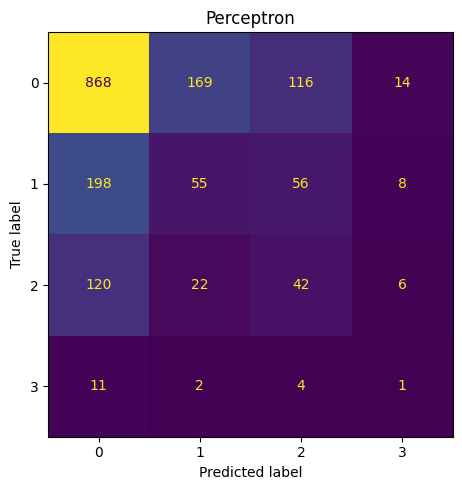

In [5]:
dummy = Pipeline([('prep', clone(preprocessor)),
                  ('clf', DummyClassifier(strategy='most_frequent'))]).fit(X_train, y_train)
risultati.append(valuta('Dummy (most frequent)', dummy, stampa=False))

perc = Pipeline([('prep', clone(preprocessor)),
                 ('clf', Perceptron(random_state=RANDOM_STATE))]).fit(X_train, y_train)
risultati.append(valuta('Perceptron', perc))   # nessuna predict_proba -> ROC AUC non calcolata
plot_confusion(perc.predict(X_test), 'Perceptron')

Addestramento: 13.2s, 300 iterazioni
=== MLP default ===
{'accuracy': 0.583, 'balanced_acc': 0.293, 'f1_macro': 0.293, 'roc_auc': 0.598, 'f1_0': 0.74, 'f1_1': 0.226, 'f1_2': 0.207, 'f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.727     0.754     0.740      1167
           1      0.235     0.218     0.226       317
           2      0.215     0.200     0.207       190
           3      0.000     0.000     0.000        18

    accuracy                          0.583      1692
   macro avg      0.294     0.293     0.293      1692
weighted avg      0.570     0.583     0.576      1692



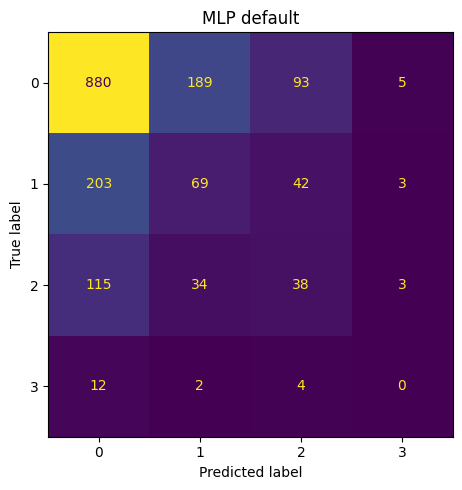

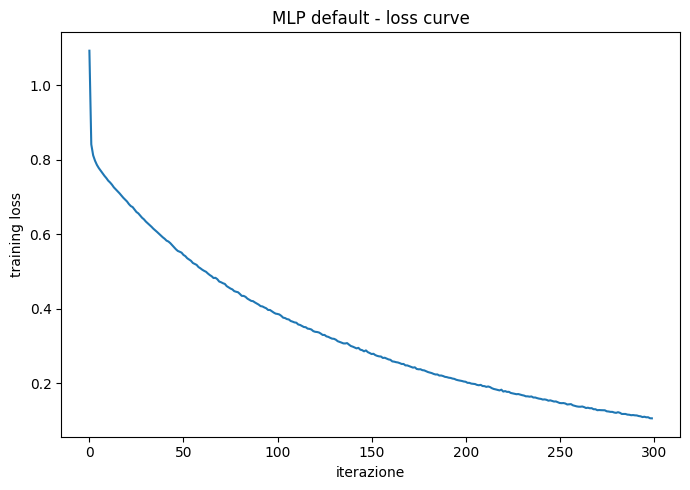

In [6]:
t0 = time.time()
mlp_base = Pipeline([('prep', clone(preprocessor)),
                     ('clf', MLPClassifier(random_state=RANDOM_STATE, max_iter=300))])
mlp_base.fit(X_train, y_train)
print(f'Addestramento: {time.time() - t0:.1f}s, {mlp_base.named_steps["clf"].n_iter_} iterazioni')
risultati.append(valuta('MLP default', mlp_base))
plot_confusion(mlp_base.predict(X_test), 'MLP default')

plt.plot(mlp_base.named_steps['clf'].loss_curve_)
plt.xlabel('iterazione'); plt.ylabel('training loss'); plt.title('MLP default - loss curve')
plt.tight_layout(); plt.show()

**Commento.** Il Dummy ha accuracy 0.690 ma F1-macro 0.204, perché non predice mai le classi 1, 2 e 3: è il motivo per cui la scelta dei modelli si fa sulla F1-macro. Perceptron (0.294) e MLP di default (0.293) hanno praticamente la stessa F1-macro (dalle confusion matrix: il Perceptron distribuisce un po' di più le predizioni sulle classi minoritarie e individua 1 dei 18 casi della classe 3, che l'MLP non predice mai): **aggiungere un hidden layer, senza tuning, non porta guadagni**. Il segnale nei dati è debole e in gran parte già catturabile da una frontiera lineare (lo stesso indica la Logistic Regression).

La loss di training dell'MLP di default scende per tutte le 300 iterazioni senza stabilizzarsi: la rete continua ad adattarsi al training set, e la F1 sul test non migliora. È un primo segnale di **overfitting**, approfondito nella sezione 6.

📌 **Report:** riga Dummy e riga Perceptron nella tabella finale come riferimento minimo; una frase sul fatto che Perceptron ≈ MLP di default.

## 5. MLP (scikit-learn): hyper-parameter tuning

Ricerca randomizzata con 5-fold stratificata, ottimizzando la **F1-macro**.

| Parametro | Valori | Motivazione |
|---|---|---|
| `hidden_layer_sizes` | 1–2 strati, 32–128 neuroni | capacità del modello (profondità e larghezza) |
| `activation` | relu, tanh | le due attivazioni più usate per gli hidden layer (vedi slide) |
| `alpha` | 1e-4 → 1 | regolarizzazione L2 sui pesi |
| `learning_rate_init` | 1e-3, 1e-2 | passo della discesa del gradiente |
| `batch_size` | 64, 128 | dimensione dei mini-batch |
| `early_stopping` | True/False | interrompe il training quando lo score di validazione (accuracy) smette di migliorare |

**Scelte per contenere i tempi** (da citare nel report come motivazione della griglia):
- `max_iter=200`: nelle prove le reti migliori convergono (o si stabilizzano) entro 100-200 epoche;
- esclusi `learning_rate_init=1e-4` e `batch_size=32`, che rallentano molto la convergenza senza
  migliorare la F1-macro in prove preliminari;
- `logistic` escluso perché con più strati soffre di vanishing gradient (saturazione della sigmoide).

In [7]:
N_ITER_MLP = 15   # configurazioni provate (15 x 5 fold = 75 addestramenti)

param_mlp = {
    'clf__hidden_layer_sizes': [(32,), (64,), (128,), (64, 32), (128, 64)],
    'clf__activation': ['relu', 'tanh'],
    'clf__alpha': [1e-4, 1e-3, 1e-2, 1e-1, 1],
    'clf__learning_rate_init': [1e-3, 1e-2],
    'clf__batch_size': [64, 128],
    'clf__early_stopping': [True, False],
}

rs_mlp = RandomizedSearchCV(
    Pipeline([('prep', clone(preprocessor)),
              ('clf', MLPClassifier(max_iter=200, random_state=RANDOM_STATE))]),
    param_mlp, n_iter=N_ITER_MLP, scoring='f1_macro',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1)

t0 = time.time()
rs_mlp.fit(X_train, y_train)
print(f'Ricerca completata in {time.time() - t0:.0f}s')
print('Migliori parametri:', rs_mlp.best_params_)
print('F1-macro in CV:', round(rs_mlp.best_score_, 4))

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Ricerca completata in 70s
Migliori parametri: {'clf__learning_rate_init': 0.001, 'clf__hidden_layer_sizes': (32,), 'clf__early_stopping': False, 'clf__batch_size': 64, 'clf__alpha': 0.0001, 'clf__activation': 'tanh'}
F1-macro in CV: 0.2994


In [8]:
# Tabella delle configurazioni provate (da riportare nel report)
cols = ['param_' + p for p in param_mlp] + ['mean_test_score', 'std_test_score', 'rank_test_score']
tab_mlp = (pd.DataFrame(rs_mlp.cv_results_)[cols]
           .rename(columns=lambda c: c.replace('param_clf__', ''))
           .sort_values('rank_test_score'))
tab_mlp.round(4)

,hidden_layer_sizes,activation,alpha,learning_rate_init,batch_size,early_stopping,mean_test_score,std_test_score,rank_test_score
3,"(32,)",tanh,0.0001,0.001,64,False,0.2994,0.0106,1
7,"(128,)",relu,0.0100,0.001,64,False,0.2969,0.0080,2
12,"(64, 32)",relu,0.0010,0.001,64,False,0.2945,0.0125,3
13,"(64,)",relu,0.0010,0.001,128,False,0.2939,0.0150,4
14,"(64,)",relu,0.1000,0.001,64,False,0.2934,0.0082,5
2,"(64,)",relu,0.0001,0.010,128,False,0.2895,0.0077,6
4,"(64,)",relu,0.0100,0.010,64,False,0.2854,0.0184,7
5,"(128,)",relu,0.0100,0.001,64,True,0.2602,0.0197,8
1,"(32,)",tanh,0.0100,0.001,64,True,0.2597,0.0142,9
8,"(64, 32)",tanh,0.0010,0.001,128,True,0.2533,0.0168,10


In [9]:
# Effetto di early_stopping: F1-macro media in CV delle configurazioni con e senza
tab_mlp.groupby('early_stopping')['mean_test_score'].agg(['mean', 'max', 'count']).round(4)

,mean,max,count
early_stopping,,,
False,0.2933,0.2994,7
True,0.2447,0.2602,8


=== MLP tuned ===
{'accuracy': 0.598, 'balanced_acc': 0.294, 'f1_macro': 0.294, 'roc_auc': 0.589, 'f1_0': 0.756, 'f1_1': 0.23, 'f1_2': 0.189, 'f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.735     0.779     0.756      1167
           1      0.257     0.208     0.230       317
           2      0.188     0.189     0.189       190
           3      0.000     0.000     0.000        18

    accuracy                          0.598      1692
   macro avg      0.295     0.294     0.294      1692
weighted avg      0.576     0.598     0.586      1692



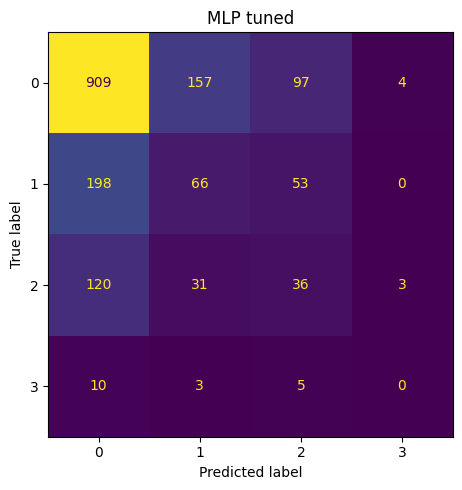

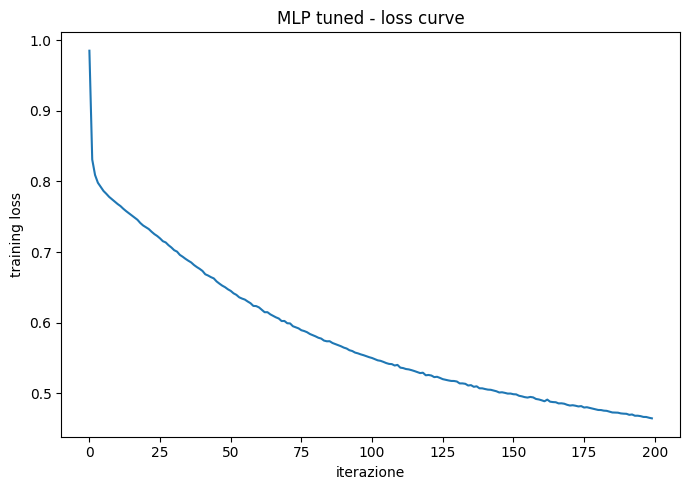

In [10]:
mlp_best = rs_mlp.best_estimator_
risultati.append(valuta('MLP tuned', mlp_best))
plot_confusion(mlp_best.predict(X_test), 'MLP tuned')

plt.plot(mlp_best.named_steps['clf'].loss_curve_)
plt.xlabel('iterazione'); plt.ylabel('training loss'); plt.title('MLP tuned - loss curve')
plt.tight_layout(); plt.show()

**Commento.**
- Miglior configurazione: **1 hidden layer da 32 neuroni, tanh, alpha=1e-4, learning rate 1e-3, batch 64, senza early stopping**, F1-macro in CV **0.299**. Sul test la F1-macro è 0.294, in linea con la CV: il tuning non ha prodotto overfitting sulla validazione.
- **Il risultato più interessante è l'effetto di `early_stopping`**: tutte le 7 configurazioni senza early stopping occupano le prime 7 posizioni (F1-macro media 0.293), tutte quelle con early stopping le ultime 8 (media 0.245). In sklearn l'early stopping monitora l'**accuracy** sulla validazione, e su un dataset sbilanciato l'accuracy è massima già quando la rete predice quasi sempre la classe 0: il training si ferma prima che la rete impari le classi minoritarie. La stessa cosa si vede in Keras (sezione 6.2).
- Le prime 7 configurazioni stanno tutte fra 0.286 e 0.299, con deviazioni standard fra i fold di 0.01-0.02: **le differenze fra architetture sono dello stesso ordine della variabilità fra i fold**. Profondità, larghezza e alpha contano poco; reti piccole (32-64 neuroni, un solo strato) bastano.
- La loss del modello finale scende ancora alla 200ª iterazione (limite `max_iter`): la rete non ha raggiunto la convergenza, ma lasciarla andare avanti farebbe solo aumentare l'adattamento al training set (vedi MLP di default, 300 iterazioni, stessa F1).
- L'MLP di sklearn non supporta `class_weight`, quindi non ha modo di dare più peso alle classi rare: la classe 3 non viene mai predetta (F1 = 0).

📌 **Report:** tabella `tab_mlp` (anche solo le prime 5 righe + le ultime 2), la tabella del confronto `early_stopping` True/False, e la spiegazione del perché l'early stopping basato sull'accuracy peggiora la F1-macro.

## 6. Rete in Keras: overfitting e regolarizzazione

Con Keras si ha il controllo diretto sull'andamento del training epoca per epoca, e quindi si può studiare
l'**overfitting** e i **criteri di convergenza** che lo evitano, come chiesto dalle guidelines.

Dal training set si ritaglia un **validation set** stratificato (15%) usato per monitorare la loss durante il
training. Il preprocessor viene fittato solo sulla parte di training.

Esperimenti, tutti con la stessa architettura di partenza (128-64, ReLU, Adam):
1. **nessuna regolarizzazione**, 150 epoche → ci si aspetta overfitting;
2. **Early Stopping** sulla `val_loss`;
3. **L2** sui pesi;
4. **Dropout**;
5. **Dropout + class weight**: i pesi delle classi nella loss, come `class_weight='balanced'` usato in
   Logistic Regression e SVM (è un parametro dell'algoritmo, non una tecnica di resampling).

Partendo dalla variante 5, si provano poi altre tecniche, una alla volta:

6. **Batch Normalization** dopo ogni hidden layer;
7. **regolarizzazione L1** al posto della L2;
8. **SGD con momentum** al posto di Adam;
9. **learning rate decrescente** (`ReduceLROnPlateau`).

In [11]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE)

prep_keras = clone(preprocessor).fit(X_tr)   # fittato solo sulla parte di training
X_tr_p  = prep_keras.transform(X_tr).astype('float32')
X_val_p = prep_keras.transform(X_val).astype('float32')
X_te_p  = prep_keras.transform(X_test).astype('float32')

n_features = X_tr_p.shape[1]
n_classes = len(CLASSI)
print('Train:', X_tr_p.shape, '| Validation:', X_val_p.shape, '| Test:', X_te_p.shape)

Train: (5752, 68) | Validation: (1016, 68) | Test: (1692, 68)


In [12]:
HIDDEN = (128, 64)
EPOCHS = 150      # massimo; con early stopping il training si ferma prima
BATCH_SIZE = 128
LR = 1e-3

def make_net(n_in, n_out, hidden=HIDDEN, activation='relu', reg_type='l2', reg=0.0,
             dropout=0.0, batchnorm=False, optimizer='adam', lr=LR, momentum=0.0):
    """Rete feed-forward. Ogni hidden layer: Dense -> [BatchNorm] -> attivazione -> [Dropout]."""
    model = keras.Sequential([keras.Input(shape=(n_in,))])
    for units in hidden:
        if reg > 0:
            kr = regularizers.l1(reg) if reg_type == 'l1' else regularizers.l2(reg)
        else:
            kr = None
        model.add(layers.Dense(units, kernel_regularizer=kr))
        if batchnorm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation(activation))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(n_out, activation='softmax'))
    if optimizer == 'adam':
        opt = keras.optimizers.Adam(learning_rate=lr)
    else:
        opt = keras.optimizers.SGD(learning_rate=lr, momentum=momentum)
    model.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def build_model(**kwargs):
    return make_net(n_features, n_classes, **kwargs)


def train_and_eval(nome, model, callbacks=None, class_weight=None, epochs=EPOCHS):
    t0 = time.time()
    hist = model.fit(X_tr_p, y_tr, validation_data=(X_val_p, y_val),
                     epochs=epochs, batch_size=BATCH_SIZE, callbacks=callbacks,
                     class_weight=class_weight, verbose=0)
    n_ep = len(hist.history['loss'])
    best_ep = int(np.argmin(hist.history['val_loss'])) + 1
    print(f'{nome}: {n_ep} epoche in {time.time() - t0:.0f}s | val_loss minima all\'epoca {best_ep}')
    plot_history(hist, nome)
    y_prob = model.predict(X_te_p, verbose=0)
    y_pred = y_prob.argmax(axis=1)
    risultati.append(valuta_prob(nome, y_pred, y_prob))
    return model, hist, y_pred, y_prob

def early_stop():
    # min_delta: miglioramenti della val_loss inferiori a 1e-4 non contano come miglioramenti
    return EarlyStopping(monitor='val_loss', patience=15, min_delta=1e-4, restore_best_weights=True)

build_model().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,348 (67.77 KB)

 Trainable params: 17,348 (67.77 KB)

 Non-trainable params: 0 (0.00 B)

### 6.1 Nessuna regolarizzazione

Keras - no reg: 150 epoche in 26s | val_loss minima all'epoca 3


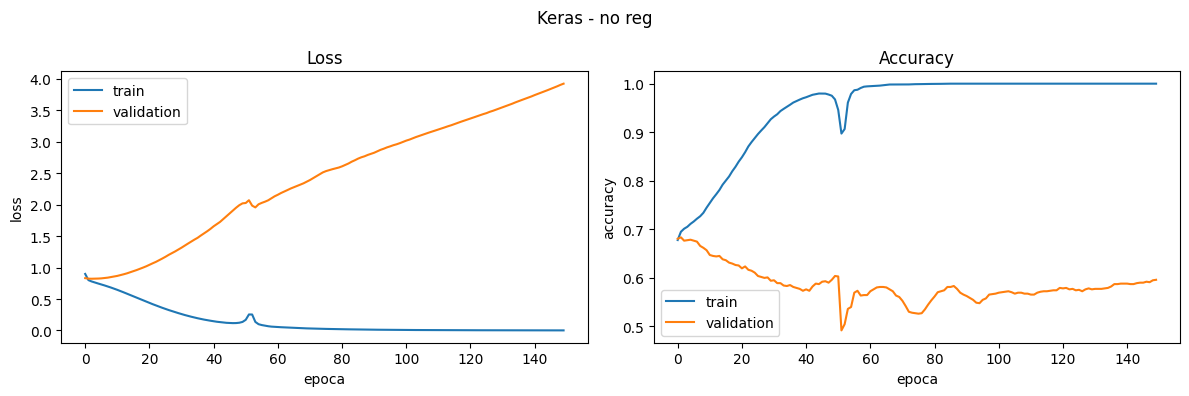

=== Keras - no reg ===
{'accuracy': 0.608, 'balanced_acc': 0.29, 'f1_macro': 0.292, 'roc_auc': 0.576, 'f1_0': 0.762, 'f1_1': 0.228, 'f1_2': 0.177, 'f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.727     0.800     0.762      1167
           1      0.247     0.211     0.228       317
           2      0.220     0.147     0.177       190
           3      0.000     0.000     0.000        18

    accuracy                          0.608      1692
   macro avg      0.299     0.290     0.292      1692
weighted avg      0.572     0.608     0.588      1692



In [13]:
keras.utils.set_random_seed(RANDOM_STATE)
m_noreg, h_noreg, _, _ = train_and_eval('Keras - no reg', build_model())

**Commento.** È l'esempio di overfitting da manuale, ed è **il grafico più importante da mettere nel report**:
- la loss di training scende fino a ~0 e l'accuracy di training arriva al 100%: la rete memorizza il training set;
- la **validation loss è minima già all'epoca 3** e poi cresce costantemente fino a ~4;
- l'accuracy di validazione scende dal 68% iniziale a circa il 60%.

Curiosamente la F1-macro sul test (0.292) non è peggiore di quella dell'MLP (0.294): una rete in overfitting predice le classi rare "per caso" più spesso, il che alza la F1 delle classi 1 e 2 ma abbassa la ROC AUC (0.576, la più bassa fra le reti), cioè peggiora la qualità delle probabilità.

📌 **Report:** grafico loss/accuracy di questa cella + frase: *"senza regolarizzazione la validation loss raggiunge il minimo dopo 3 epoche e poi diverge, mentre la training loss tende a zero"*.

### 6.2 Early Stopping

Il training si interrompe quando la `val_loss` non migliora (di almeno `min_delta=1e-4`) per `patience=15`
epoche consecutive; con `restore_best_weights=True` si tengono i pesi dell'epoca migliore.
Si monitora la loss e non l'accuracy perché l'accuracy, dominata dalla classe 0, è poco sensibile.

Keras - early stopping: 18 epoche in 4s | val_loss minima all'epoca 3


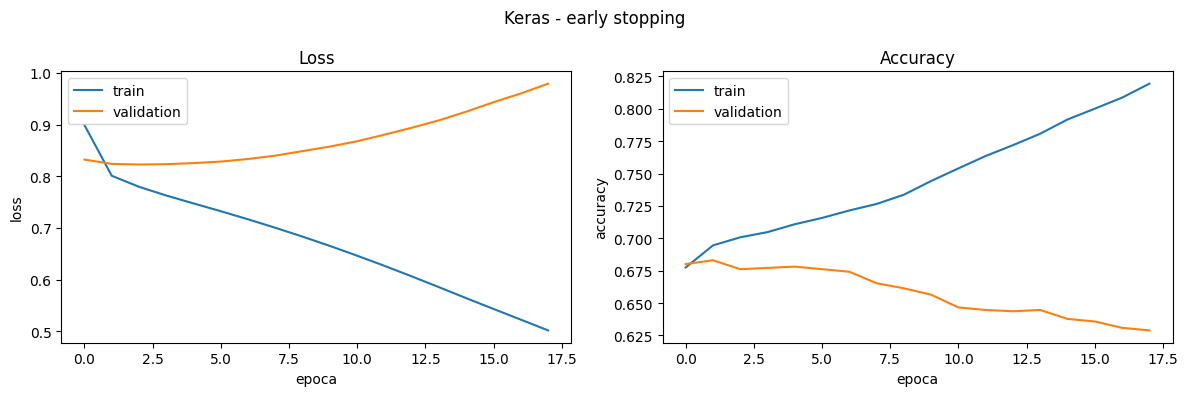

=== Keras - early stopping ===
{'accuracy': 0.693, 'balanced_acc': 0.286, 'f1_macro': 0.275, 'roc_auc': 0.671, 'f1_0': 0.822, 'f1_1': 0.072, 'f1_2': 0.204, 'f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.712     0.973     0.822      1167
           1      0.295     0.041     0.072       317
           2      0.455     0.132     0.204       190
           3      0.000     0.000     0.000        18

    accuracy                          0.693      1692
   macro avg      0.366     0.286     0.275      1692
weighted avg      0.598     0.693     0.604      1692



In [14]:
keras.utils.set_random_seed(RANDOM_STATE)
m_es, h_es, _, _ = train_and_eval('Keras - early stopping', build_model(), callbacks=[early_stop()])

**Commento.** L'early stopping ferma il training all'epoca 18 e ripristina i pesi dell'epoca 3 (minimo della validation loss). Rispetto alla rete senza regolarizzazione:
- la **ROC AUC sale da 0.576 a 0.671**: le probabilità sono molto più informative;
- ma la **F1-macro scende da 0.292 a 0.275** e la recall della classe 1 crolla al 4%: la rete ferma così presto predice quasi sempre la classe 0 (recall 0.97).

Questo è il punto chiave: **evitare l'overfitting non basta**. Con la loss non pesata, il modello "ottimo" dal punto di vista della loss è quello che sta vicino alla classe maggioritaria. Serve anche gestire lo sbilanciamento (sezione 6.5).

📌 **Report:** la contrapposizione ROC AUC ↑ / F1-macro ↓ è il risultato più interessante di questa sezione.

### 6.3 Regolarizzazione L2 (con early stopping)

Keras - L2 (0.001): 22 epoche in 6s | val_loss minima all'epoca 9


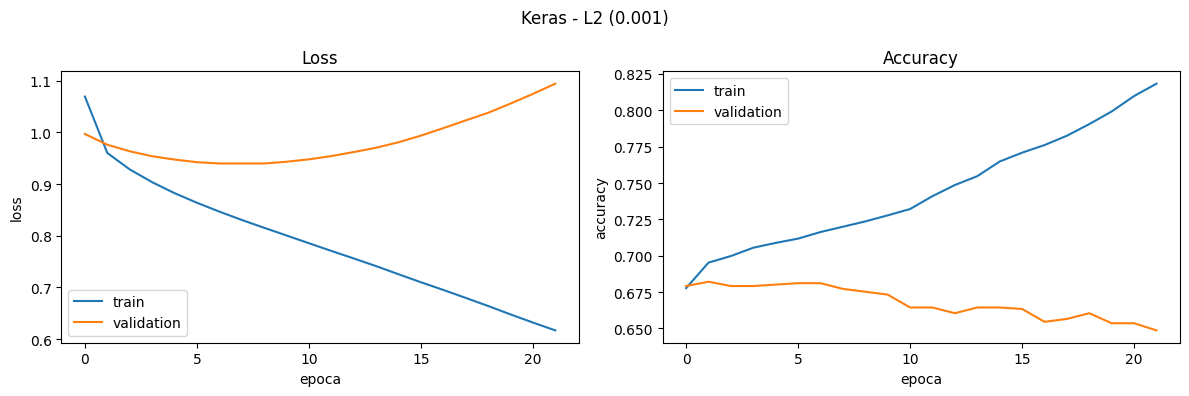

=== Keras - L2 (0.001) ===
{'accuracy': 0.687, 'balanced_acc': 0.289, 'f1_macro': 0.28, 'roc_auc': 0.69, 'f1_0': 0.819, 'f1_1': 0.1, 'f1_2': 0.202, 'f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.716     0.958     0.819      1167
           1      0.306     0.060     0.100       317
           2      0.382     0.137     0.202       190
           3      0.000     0.000     0.000        18

    accuracy                          0.687      1692
   macro avg      0.351     0.289     0.280      1692
weighted avg      0.594     0.687     0.607      1692



In [15]:
L2_REG = 1e-3

keras.utils.set_random_seed(RANDOM_STATE)
m_l2, h_l2, _, _ = train_and_eval(f'Keras - L2 ({L2_REG})', build_model(reg_type='l2', reg=L2_REG),
                                  callbacks=[early_stop()])

### 6.4 Dropout (con early stopping)

Keras - dropout (0.3): 20 epoche in 4s | val_loss minima all'epoca 5


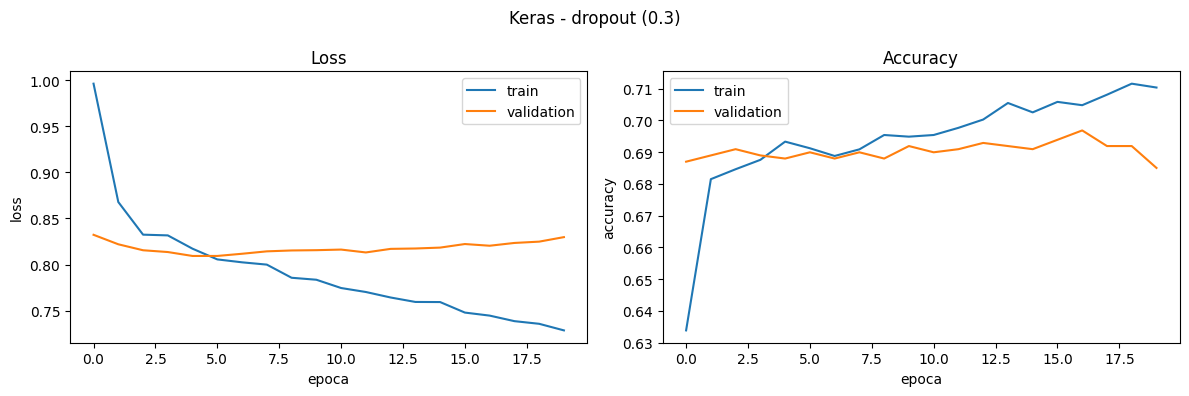

=== Keras - dropout (0.3) ===
{'accuracy': 0.689, 'balanced_acc': 0.256, 'f1_macro': 0.218, 'roc_auc': 0.678, 'f1_0': 0.816, 'f1_1': 0.019, 'f1_2': 0.039, 'f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.693     0.993     0.816      1167
           1      1.000     0.009     0.019       317
           2      0.250     0.021     0.039       190
           3      0.000     0.000     0.000        18

    accuracy                          0.689      1692
   macro avg      0.486     0.256     0.218      1692
weighted avg      0.693     0.689     0.571      1692



In [16]:
DROPOUT = 0.3

keras.utils.set_random_seed(RANDOM_STATE)
m_do, h_do, _, _ = train_and_eval(f'Keras - dropout ({DROPOUT})', build_model(dropout=DROPOUT),
                                  callbacks=[early_stop()])

**Commento.**
- **L2 (1e-3)**: sposta il minimo della validation loss dall'epoca 3 all'epoca 9 e rallenta la divergenza (curva verde nel grafico di confronto). Dà la **ROC AUC più alta di tutti i modelli (0.690)** e una F1-macro di 0.280, di poco migliore del solo early stopping (0.275).
- **Dropout (0.3)**: la validation loss resta la più bassa e piatta (curva rossa), quindi è la regolarizzazione più efficace contro l'overfitting. Però la rete predice quasi solo la classe 0 (recall 0.99) e la F1-macro è la peggiore (0.218).

Entrambe le tecniche riducono l'overfitting, ma senza pesi di classe spingono il modello verso la classe maggioritaria: **più la rete è regolarizzata, più si avvicina al Dummy in termini di predizioni**.

📌 **Report:** il grafico di confronto delle validation loss (sezione 6.6) riassume L2 e Dropout meglio delle singole curve.

### 6.5 Dropout + class weight

Keras accetta `class_weight`: gli errori sulle classi rare pesano di più nella loss, in modo inversamente
proporzionale alla frequenza della classe (stessa logica di `class_weight='balanced'` in LR e SVM).

Questa variante è il **riferimento** per gli esperimenti 6.6–6.9.

Pesi: {0: 0.36, 1: 1.33, 2: 2.22, 3: 24.37}
Keras - dropout + class weight: 42 epoche in 6s | val_loss minima all'epoca 27


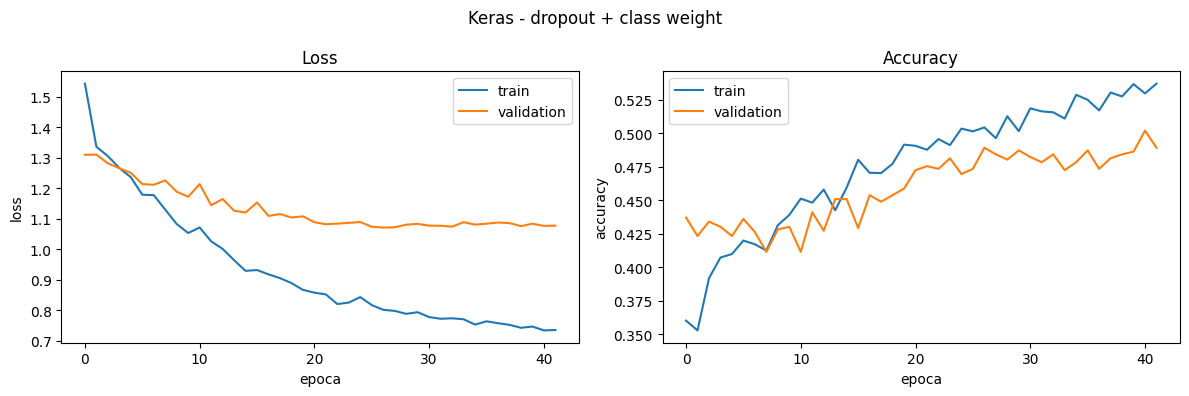

=== Keras - dropout + class weight ===
{'accuracy': 0.499, 'balanced_acc': 0.342, 'f1_macro': 0.304, 'roc_auc': 0.661, 'f1_0': 0.668, 'f1_1': 0.23, 'f1_2': 0.285, 'f1_3': 0.032}
              precision    recall  f1-score   support

           0      0.790     0.578     0.668      1167
           1      0.232     0.227     0.230       317
           2      0.198     0.505     0.285       190
           3      0.023     0.056     0.032        18

    accuracy                          0.499      1692
   macro avg      0.311     0.342     0.304      1692
weighted avg      0.611     0.499     0.536      1692



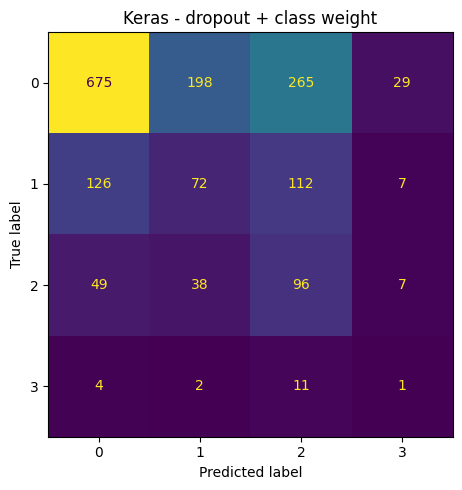

In [17]:
pesi = compute_class_weight('balanced', classes=np.array(CLASSI), y=y_tr)
class_weight = dict(zip(CLASSI, pesi))
print('Pesi:', {k: round(float(v), 2) for k, v in class_weight.items()})

keras.utils.set_random_seed(RANDOM_STATE)
m_cw, h_cw, y_pred_cw, y_prob_cw = train_and_eval(
    'Keras - dropout + class weight', build_model(dropout=DROPOUT),
    callbacks=[early_stop()], class_weight=class_weight)
plot_confusion(y_pred_cw, 'Keras - dropout + class weight')

**Commento.** Con i pesi delle classi (classe 0: 0.36, classe 3: 24.4) il comportamento cambia completamente:
- la **F1-macro sale a 0.304** (la migliore fra le varianti 6.1–6.5) e la balanced accuracy a 0.342;
- la recall della classe 2 passa dal 2% (dropout senza pesi) al **51%**, quella della classe 1 al 23%;
- la classe 3 viene finalmente predetta, anche se con F1 di appena 0.03;
- l'accuracy scende a 0.499, perché molti soggetti della classe 0 vengono assegnati alle classi superiori.

La validation loss (curva viola) parte più alta, perché è pesata, ma scende in modo regolare fino all'epoca 27 senza divergere: **dropout + early stopping controllano l'overfitting, il class weight compensa lo sbilanciamento**. È la stessa conclusione della Logistic Regression con `class_weight='balanced'`.

📌 **Report:** confusion matrix di questa cella confrontata con quella della rete senza pesi.

### 6.6 Batch Normalization

Un layer `BatchNormalization` dopo ogni hidden layer (prima dell'attivazione) normalizza gli input del layer
successivo su ogni mini-batch: rende il training più stabile e veloce, e ha un leggero effetto regolarizzante.

Keras - cw + batch norm: 78 epoche in 14s | val_loss minima all'epoca 63


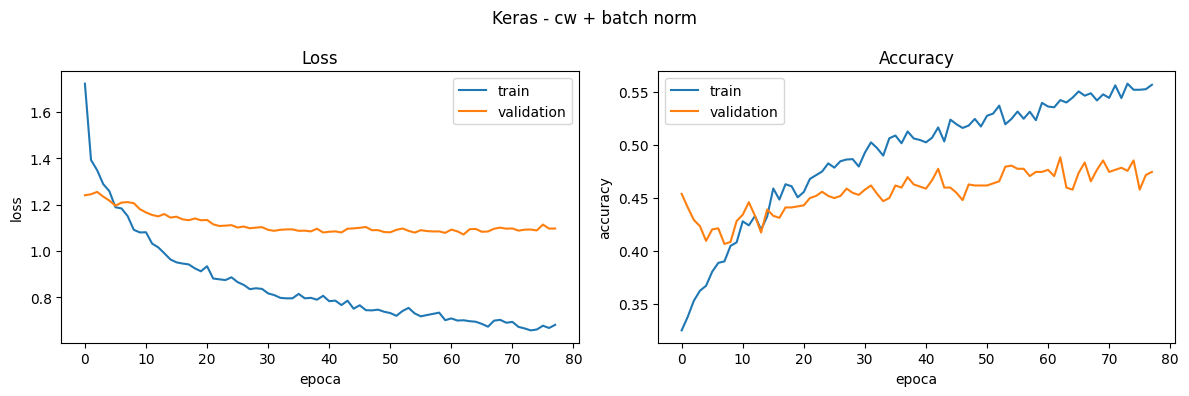

=== Keras - cw + batch norm ===
{'accuracy': 0.506, 'balanced_acc': 0.349, 'f1_macro': 0.312, 'roc_auc': 0.64, 'f1_0': 0.662, 'f1_1': 0.285, 'f1_2': 0.301, 'f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.804     0.562     0.662      1167
           1      0.252     0.328     0.285       317
           2      0.214     0.505     0.301       190
           3      0.000     0.000     0.000        18

    accuracy                          0.506      1692
   macro avg      0.318     0.349     0.312      1692
weighted avg      0.626     0.506     0.544      1692



In [18]:
keras.utils.set_random_seed(RANDOM_STATE)
m_bn, h_bn, _, _ = train_and_eval(
    'Keras - cw + batch norm', build_model(dropout=DROPOUT, batchnorm=True),
    callbacks=[early_stop()], class_weight=class_weight)

### 6.7 Regolarizzazione L1

La penalità L1 (somma dei valori assoluti dei pesi) spinge molti pesi esattamente a zero: è una forma di
selezione implicita delle feature, potenzialmente utile con 68 feature e un segnale debole.

Keras - cw + L1 (0.001): 108 epoche in 13s | val_loss minima all'epoca 93


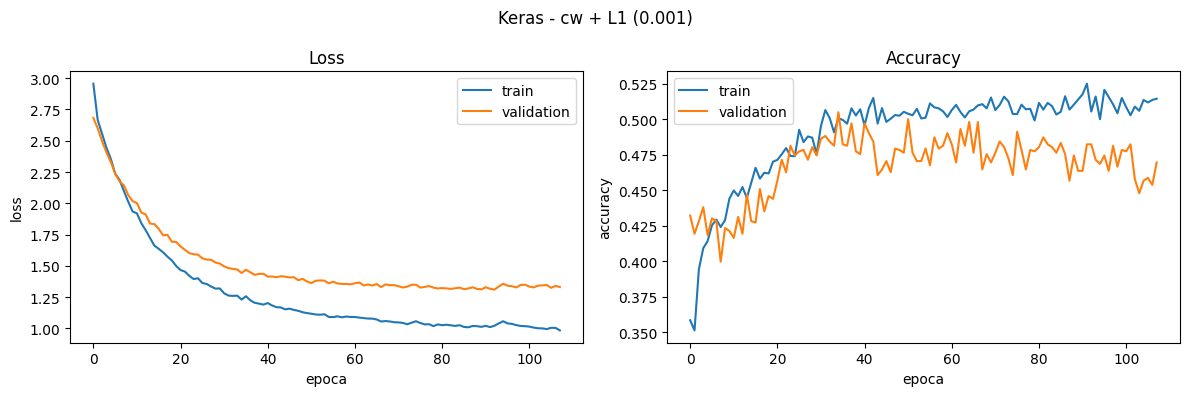

=== Keras - cw + L1 (0.001) ===
{'accuracy': 0.503, 'balanced_acc': 0.341, 'f1_macro': 0.302, 'roc_auc': 0.651, 'f1_0': 0.672, 'f1_1': 0.243, 'f1_2': 0.292, 'f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.806     0.576     0.672      1167
           1      0.257     0.230     0.243       317
           2      0.197     0.558     0.292       190
           3      0.000     0.000     0.000        18

    accuracy                          0.503      1692
   macro avg      0.315     0.341     0.302      1692
weighted avg      0.626     0.503     0.542      1692



In [19]:
L1_REG = 1e-3

keras.utils.set_random_seed(RANDOM_STATE)
m_l1, h_l1, _, _ = train_and_eval(
    f'Keras - cw + L1 ({L1_REG})', build_model(dropout=DROPOUT, reg_type='l1', reg=L1_REG),
    callbacks=[early_stop()], class_weight=class_weight)

### 6.8 SGD con momentum

Discesa del gradiente stocastica classica con **momentum** (vista a lezione) al posto di Adam.
Con SGD serve un learning rate più alto (1e-2): con 1e-3 la convergenza sarebbe molto lenta.

Keras - cw + SGD momentum 0.9: 30 epoche in 4s | val_loss minima all'epoca 15


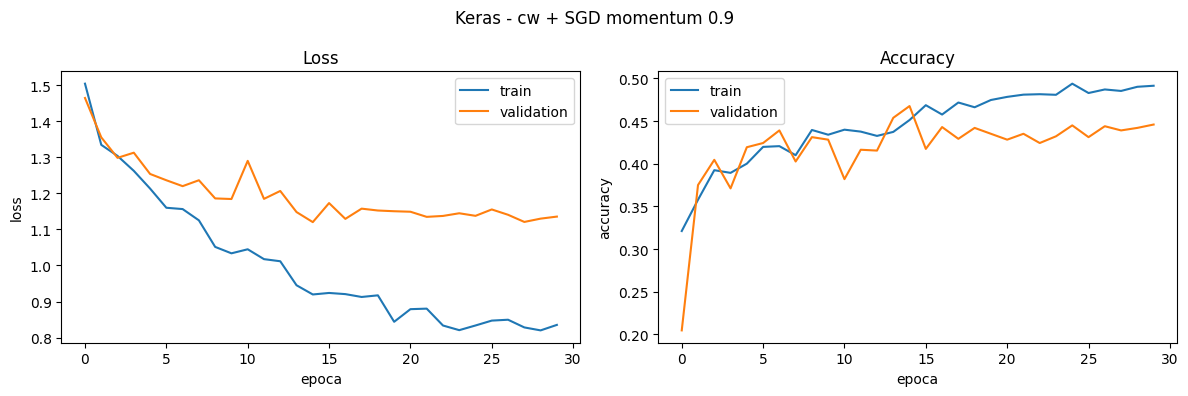

=== Keras - cw + SGD momentum 0.9 ===
{'accuracy': 0.475, 'balanced_acc': 0.352, 'f1_macro': 0.292, 'roc_auc': 0.666, 'f1_0': 0.651, 'f1_1': 0.194, 'f1_2': 0.291, 'f1_3': 0.031}
              precision    recall  f1-score   support

           0      0.806     0.547     0.651      1167
           1      0.244     0.161     0.194       317
           2      0.193     0.589     0.291       190
           3      0.018     0.111     0.031        18

    accuracy                          0.475      1692
   macro avg      0.315     0.352     0.292      1692
weighted avg      0.623     0.475     0.519      1692



In [20]:
keras.utils.set_random_seed(RANDOM_STATE)
m_sgd, h_sgd, _, _ = train_and_eval(
    'Keras - cw + SGD momentum 0.9',
    build_model(dropout=DROPOUT, optimizer='sgd', lr=1e-2, momentum=0.9),
    callbacks=[early_stop()], class_weight=class_weight)

### 6.9 Learning rate decrescente

`ReduceLROnPlateau` dimezza il learning rate quando la `val_loss` non migliora per 5 epoche: con passi più
piccoli la rete può avvicinarsi meglio al minimo prima che intervenga l'early stopping (patience 15).

Keras - cw + ReduceLROnPlateau: 42 epoche in 6s | val_loss minima all'epoca 27


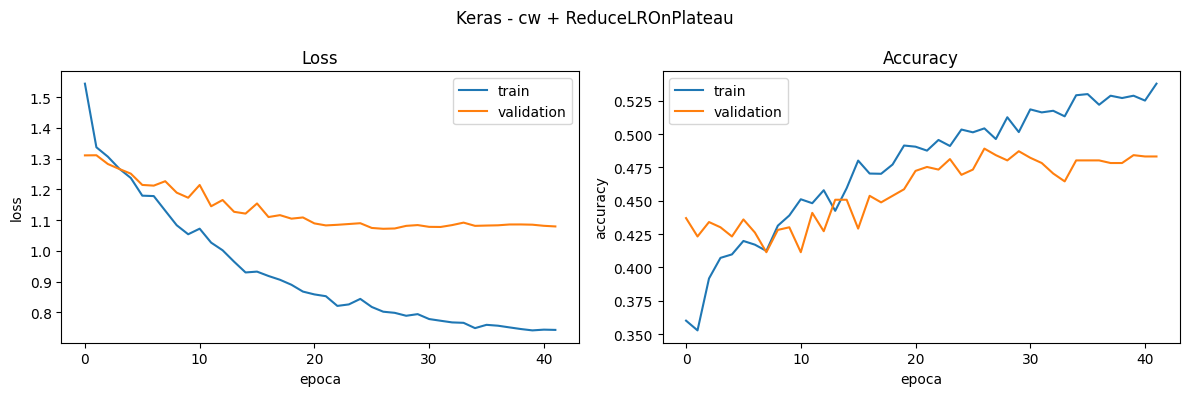

=== Keras - cw + ReduceLROnPlateau ===
{'accuracy': 0.499, 'balanced_acc': 0.342, 'f1_macro': 0.304, 'roc_auc': 0.661, 'f1_0': 0.668, 'f1_1': 0.23, 'f1_2': 0.285, 'f1_3': 0.032}
              precision    recall  f1-score   support

           0      0.790     0.578     0.668      1167
           1      0.232     0.227     0.230       317
           2      0.198     0.505     0.285       190
           3      0.023     0.056     0.032        18

    accuracy                          0.499      1692
   macro avg      0.311     0.342     0.304      1692
weighted avg      0.611     0.499     0.536      1692



In [21]:
def reduce_lr():
    return ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5)

keras.utils.set_random_seed(RANDOM_STATE)
m_rlr, h_rlr, _, _ = train_and_eval(
    'Keras - cw + ReduceLROnPlateau', build_model(dropout=DROPOUT),
    callbacks=[early_stop(), reduce_lr()], class_weight=class_weight)

**Commento sulle varianti 6.6–6.9** (tutte confrontate con la variante 6.5, F1-macro 0.304):

| Variante | F1-macro | Bal. acc. | Epoche (minimo val_loss) | Effetto |
|---|---|---|---|---|
| riferimento: dropout + class weight | 0.304 | 0.342 | 42 (27) | – |
| + Batch Normalization | **0.312** | 0.349 | 78 (63) | leggero miglioramento sulle classi 1 e 2, ma perde la classe 3 |
| L1 (1e-3) | 0.302 | 0.341 | 108 (93) | equivalente o di poco peggiore; la classe 3 non viene più predetta |
| SGD + momentum 0.9 | 0.292 | **0.352** | 30 (15) | F1-macro più bassa, ma balanced accuracy più alta |
| + ReduceLROnPlateau | 0.304 | 0.342 | 42 (27) | **nessun effetto**: risultati identici |

- **Batch Normalization** è l'unica tecnica che migliora un po' la F1-macro (+0.008): la F1 sale per la classe 1 (da 0.23 a 0.29) e la classe 2 (da 0.29 a 0.30), ma la rete **non predice più correttamente nessun caso della classe 3** e la ROC AUC scende (da 0.661 a 0.640). Il guadagno è piccolo e non uniforme fra le metriche. Rende il training più regolare (curva arancione) e lo allunga: la rete continua a migliorare più a lungo.
- **L1** fa partire la validation loss molto più in alto (curva verde) perché la loss riportata da Keras include la penalità di regolarizzazione: non è confrontabile in valore assoluto con le altre curve. Converge lentamente (108 epoche) e, azzerando molti pesi, finisce per non individuare nessun caso della classe 3. Con un segnale già debole, eliminare feature non porta benefici.
- **SGD con momentum** converge in meno epoche, con una curva più rumorosa (passi meno adattivi di Adam). Classifica più esempi nelle classi rare (balanced accuracy più alta) ma a scapito della precision.
- **ReduceLROnPlateau** non cambia nulla, ed è un risultato da spiegare: il learning rate verrebbe dimezzato dopo l'epoca 32 (5 epoche senza miglioramento dopo il minimo all'epoca 27), ma l'early stopping ripristina i pesi dell'epoca 27, **prima** di qualunque riduzione. Il modello finale è quindi identico.

📌 **Report:** questa tabella e il grafico di destra della sezione 6.10. Conclusione: *una volta gestiti overfitting (dropout + early stopping) e sbilanciamento (class weight), le tecniche di ottimizzazione aggiuntive non portano miglioramenti significativi: il limite è nei dati, non nell'addestramento della rete.*

### 6.10 Confronto delle varianti Keras

In [22]:
tab_keras = pd.DataFrame([r for r in risultati if r['modello'].startswith('Keras')]).set_index('modello')
tab_keras.round(3)

,accuracy,balanced_acc,f1_macro,roc_auc,f1_0,f1_1,f1_2,f1_3
modello,,,,,,,,
Keras - no reg,0.608,0.290,0.292,0.576,0.762,0.228,0.177,0.000
Keras - early stopping,0.693,0.286,0.275,0.671,0.822,0.072,0.204,0.000
Keras - L2 (0.001),0.687,0.289,0.280,0.690,0.819,0.100,0.202,0.000
Keras - dropout (0.3),0.689,0.256,0.218,0.678,0.816,0.019,0.039,0.000
Keras - dropout + class weight,0.499,0.342,0.304,0.661,0.668,0.230,0.285,0.032
Keras - cw + batch norm,0.506,0.349,0.312,0.640,0.662,0.285,0.301,0.000
Keras - cw + L1 (0.001),0.503,0.341,0.302,0.651,0.672,0.243,0.292,0.000
Keras - cw + SGD momentum 0.9,0.475,0.352,0.292,0.666,0.651,0.194,0.291,0.031
Keras - cw + ReduceLROnPlateau,0.499,0.342,0.304,0.661,0.668,0.230,0.285,0.032


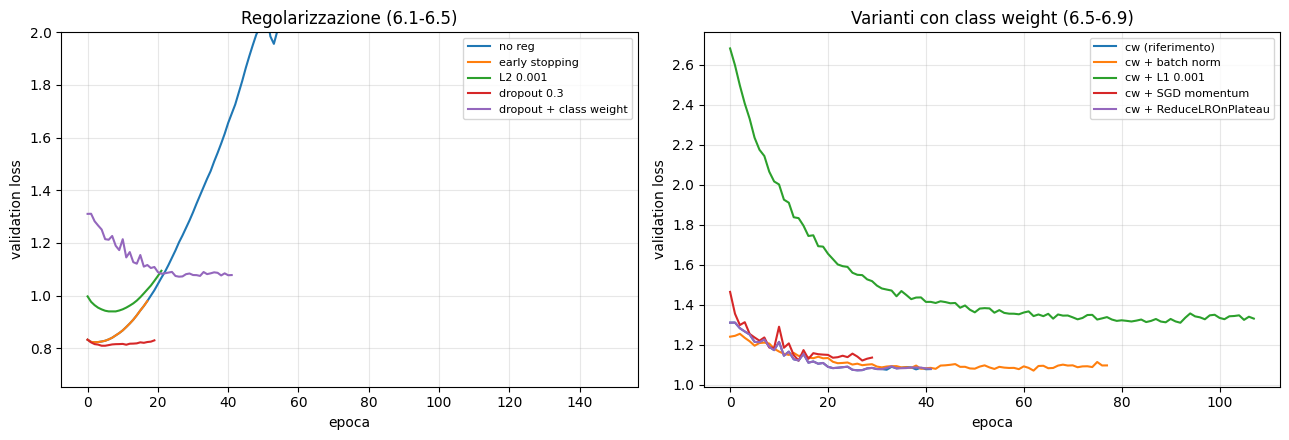

In [23]:
# Curve di validation loss a confronto (grafici utili per il report)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for nome, h in [('no reg', h_noreg), ('early stopping', h_es), (f'L2 {L2_REG}', h_l2),
                (f'dropout {DROPOUT}', h_do), ('dropout + class weight', h_cw)]:
    axes[0].plot(h.history['val_loss'], label=nome)
axes[0].set_ylim(top=2); axes[0].set_title('Regolarizzazione (6.1-6.5)')

for nome, h in [('cw (riferimento)', h_cw), ('cw + batch norm', h_bn), (f'cw + L1 {L1_REG}', h_l1),
                ('cw + SGD momentum', h_sgd), ('cw + ReduceLROnPlateau', h_rlr)]:
    axes[1].plot(h.history['val_loss'], label=nome)
axes[1].set_title('Varianti con class weight (6.5-6.9)')

for ax in axes:
    ax.set_xlabel('epoca'); ax.set_ylabel('validation loss'); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Commento.**
- **Grafico di sinistra** (sezioni 6.1–6.5): i tre comportamenti tipici. **no reg** (blu) diverge dopo poche epoche → overfitting; **early stopping / L2 / dropout** fermano il training vicino al minimo, con L2 che sposta il minimo più avanti e dropout che tiene la curva più piatta; **dropout + class weight** (viola) ha la loss su un'altra scala (è pesata) ma scende in modo stabile.
- **Grafico di destra** (sezioni 6.5–6.9): Batch Normalization, SGD e ReduceLROnPlateau seguono quasi la stessa curva del riferimento, con lo stesso livello finale di loss (circa 1.08–1.13): nessuna di queste tecniche trova un minimo sostanzialmente migliore. L1 è fuori scala perché la sua loss include la penalità.

📌 **Report — risposta alla domanda delle guidelines** *"what are the parameter sets or the convergence criteria which avoid overfitting?"*: early stopping sulla validation loss (con `restore_best_weights` e `min_delta`), dropout 0.3-0.4 e L2 1e-3/1e-2. Ma su questo dataset evitare l'overfitting non basta: senza `class_weight` le reti regolarizzate collassano sulla classe 0.

## 7. Confronto fra architetture

Tre reti di dimensione crescente, tutte con la stessa ricetta di training (dropout 0.3, class weight,
early stopping), per vedere quanto conta la **capacità** del modello:

| Rete | Hidden layer |
|---|---|
| piccola | 16 |
| media | 64 - 32 |
| grande | 256 - 128 - 64 |

Rete piccola (16,): 1,172 parametri
Keras - rete piccola (16,): 75 epoche in 8s | val_loss minima all'epoca 60


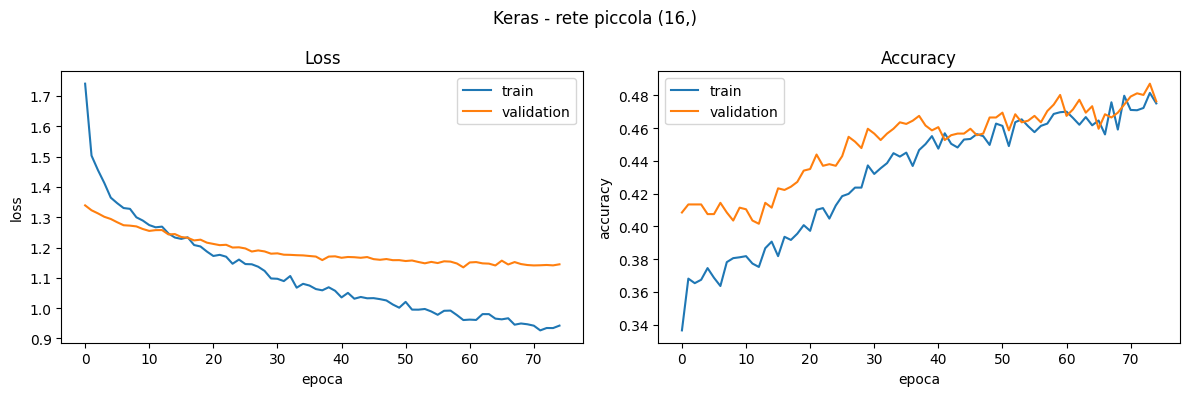

=== Keras - rete piccola (16,) ===
{'accuracy': 0.515, 'balanced_acc': 0.347, 'f1_macro': 0.318, 'roc_auc': 0.664, 'f1_0': 0.684, 'f1_1': 0.26, 'f1_2': 0.315, 'f1_3': 0.013}
              precision    recall  f1-score   support

           0      0.796     0.600     0.684      1167
           1      0.284     0.240     0.260       317
           2      0.231     0.495     0.315       190
           3      0.007     0.056     0.013        18

    accuracy                          0.515      1692
   macro avg      0.330     0.347     0.318      1692
weighted avg      0.628     0.515     0.556      1692

Rete media (64, 32): 6,628 parametri
Keras - rete media (64, 32): 53 epoche in 6s | val_loss minima all'epoca 38


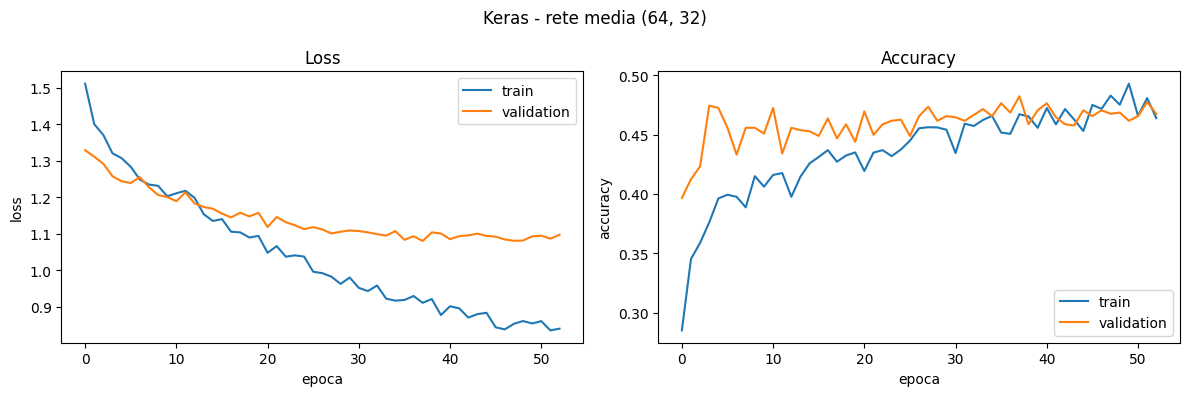

=== Keras - rete media (64, 32) ===
{'accuracy': 0.504, 'balanced_acc': 0.385, 'f1_macro': 0.321, 'roc_auc': 0.665, 'f1_0': 0.668, 'f1_1': 0.233, 'f1_2': 0.316, 'f1_3': 0.065}
              precision    recall  f1-score   support

           0      0.799     0.574     0.668      1167
           1      0.256     0.215     0.233       317
           2      0.217     0.584     0.316       190
           3      0.040     0.167     0.065        18

    accuracy                          0.504      1692
   macro avg      0.328     0.385     0.321      1692
weighted avg      0.623     0.504     0.541      1692

Rete grande (256, 128, 64): 59,076 parametri
Keras - rete grande (256, 128, 64): 36 epoche in 6s | val_loss minima all'epoca 21


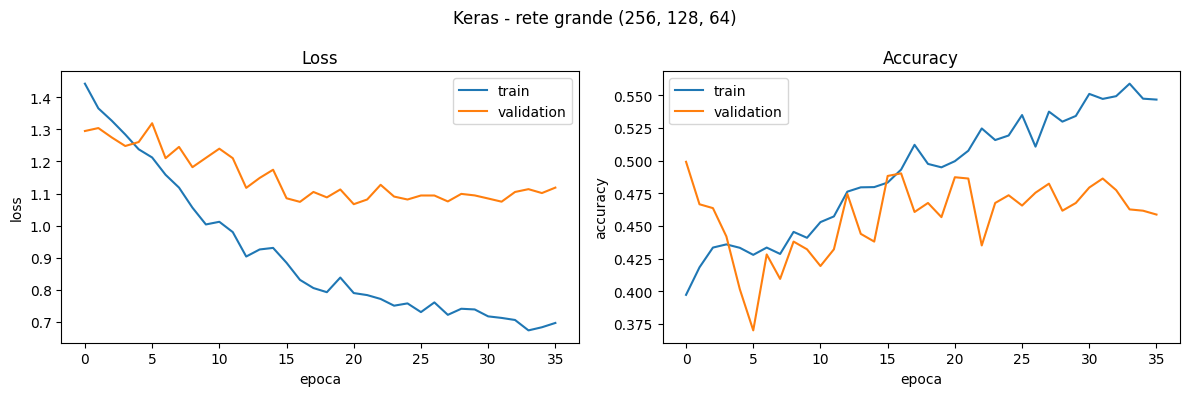

=== Keras - rete grande (256, 128, 64) ===
{'accuracy': 0.515, 'balanced_acc': 0.359, 'f1_macro': 0.314, 'roc_auc': 0.659, 'f1_0': 0.677, 'f1_1': 0.258, 'f1_2': 0.32, 'f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.810     0.582     0.677      1167
           1      0.274     0.243     0.258       317
           2      0.217     0.611     0.320       190
           3      0.000     0.000     0.000        18

    accuracy                          0.515      1692
   macro avg      0.325     0.359     0.314      1692
weighted avg      0.635     0.515     0.551      1692



In [24]:
ARCHITETTURE = {'piccola': (16,), 'media': (64, 32), 'grande': (256, 128, 64)}
h_arch = {}

for nome, hidden in ARCHITETTURE.items():
    keras.utils.set_random_seed(RANDOM_STATE)
    model = build_model(hidden=hidden, dropout=DROPOUT)
    print(f'Rete {nome} {hidden}: {model.count_params():,} parametri')
    _, h_arch[nome], _, _ = train_and_eval(f'Keras - rete {nome} {hidden}', model,
                                           callbacks=[early_stop()], class_weight=class_weight)

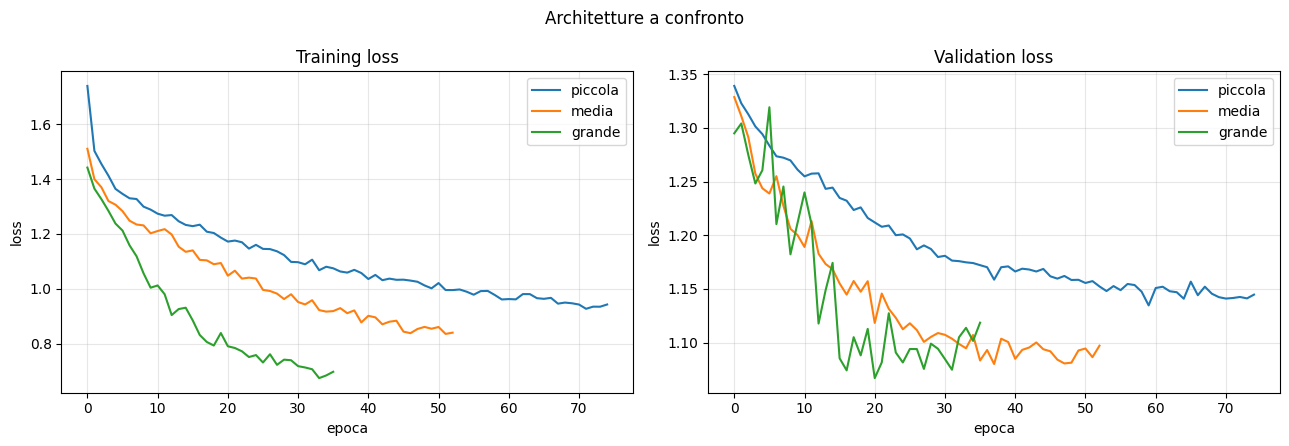

,accuracy,balanced_acc,f1_macro,roc_auc,f1_0,f1_1,f1_2,f1_3
modello,,,,,,,,
"Keras - rete piccola (16,)",0.515,0.347,0.318,0.664,0.684,0.260,0.315,0.013
"Keras - rete media (64, 32)",0.504,0.385,0.321,0.665,0.668,0.233,0.316,0.065
"Keras - rete grande (256, 128, 64)",0.515,0.359,0.314,0.659,0.677,0.258,0.320,0.000


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for nome, h in h_arch.items():
    axes[0].plot(h.history['loss'], label=nome)
    axes[1].plot(h.history['val_loss'], label=nome)
axes[0].set_title('Training loss'); axes[1].set_title('Validation loss')
for ax in axes:
    ax.set_xlabel('epoca'); ax.set_ylabel('loss'); ax.legend(); ax.grid(alpha=.3)
plt.suptitle('Architetture a confronto'); plt.tight_layout(); plt.show()

pd.DataFrame([r for r in risultati if 'rete' in r['modello']]).set_index('modello').round(3)

**Commento.**

| Rete | Parametri | Epoche (minimo val_loss) | F1-macro | Bal. acc. | F1 classe 3 |
|---|---|---|---|---|---|
| piccola (16) | 1.172 | 75 (60) | 0.318 | 0.347 | 0.013 |
| media (64-32) | 6.628 | 53 (38) | **0.321** | **0.385** | **0.065** |
| grande (256-128-64) | 59.076 | 36 (21) | 0.314 | 0.359 | 0.000 |

- **Le tre reti hanno quasi la stessa F1-macro** (0.314–0.321), nonostante il numero di parametri vari di un fattore 50. La capacità del modello non è il fattore limitante.
- Il grafico mostra il classico compromesso: la rete **grande** abbassa la training loss molto più velocemente (fino a 0.67) ma la validation loss diventa instabile e risale dopo l'epoca 21 → **inizio di overfitting**, e l'early stopping interviene prima. La rete **piccola** impara lentamente e la sua validation loss resta la più alta (circa 1.14): leggero **underfitting**. La rete **media** è il punto di equilibrio, con la validation loss più bassa e regolare.
- La rete media è anche quella che individua più casi della classe 3 (F1 0.065), ma su 18 esempi la differenza è di un paio di casi.
- Tutte e tre superano la variante 6.5 (128-64, F1-macro 0.304): reti più piccole o diverse dalla 128-64 vanno leggermente meglio, coerentemente con quanto trovato dal tuning (sezione 8: la configurazione migliore ha un solo hidden layer da 64).

📌 **Report:** tabella + grafico training/validation loss delle tre architetture. È una delle figure migliori per spiegare overfitting e underfitting.

## 8. Rete in Keras: hyper-parameter tuning

Tuning con `KerasClassifier` di **scikeras**, che rende la rete compatibile con `Pipeline` e
`RandomizedSearchCV`. (Nel notebook di lezione si usa `build_fn=`: nelle versioni recenti di scikeras il
parametro si chiama `model=`.)

Si usa la stessa 5-fold stratificata del tuning dell'MLP, così i due tuning sono confrontabili.
Ogni configurazione è addestrata con early stopping (`patience=10`, `min_delta=1e-4`) su un 15% del training del fold.

**Scelta della griglia.** La griglia contiene architettura, attivazione, L2, dropout, learning rate, batch size e
`class_weight`, con ottimizzatore Adam. Le tecniche delle sezioni 6.6–6.9 (Batch Normalization, L1, SGD con
momentum, ReduceLROnPlateau) **non sono incluse**: nel confronto controllato non hanno migliorato la rete di
riferimento in modo apprezzabile, e allargare lo spazio di ricerca a parità di configurazioni provate peggiora
l'esplorazione.

> **Prova con la griglia allargata** (da citare nel report). Aggiungendo alla griglia tipo di regolarizzazione
> (L1/L2), Batch Normalization, ottimizzatore (Adam / SGD con momentum 0.5-0.9) e ReduceLROnPlateau, con 15
> configurazioni × 5 fold, la ricerca ha richiesto circa 12 minuti e ha trovato una configurazione **peggiore**:
> F1-macro 0.309 in CV e 0.309 sul test, contro 0.311 e 0.320 della griglia mirata. Anche lì le medie per
> parametro confermano la sezione 6: `class_weight` balanced 0.287 vs None 0.248; L2 0.291 vs L1 0.263;
> Adam ≈ SGD (0.268 vs 0.270); Batch Normalization +0.015; ReduceLROnPlateau nessun miglioramento.

**Scelte per contenere i tempi** (da citare nel report): al massimo 100 epoche, `batch_size` 64 o 128,
10 configurazioni. Con l'early stopping quasi tutte le configurazioni si fermano molto prima delle 100 epoche.

In [26]:
N_ITER_KERAS = 10   # configurazioni provate (10 x 5 fold = 50 addestramenti)

# scikeras richiede che gli iperparametri compaiano esplicitamente nella firma della funzione
def build_model_sk(meta, hidden, activation, l2_reg, dropout, lr):
    return make_net(meta['n_features_in_'], meta['n_classes_'], hidden=hidden, activation=activation,
                    reg_type='l2', reg=l2_reg, dropout=dropout, optimizer='adam', lr=lr)

keras_clf = KerasClassifier(
    model=build_model_sk, epochs=100, batch_size=128, verbose=0, validation_split=0.15,
    callbacks=[EarlyStopping(monitor='val_loss', patience=10, min_delta=1e-4, restore_best_weights=True)],
    random_state=RANDOM_STATE,
    # valori di default degli iperparametri della rete (sovrascritti dalla ricerca)
    model__hidden=(64,), model__activation='relu', model__l2_reg=0.0, model__dropout=0.0, model__lr=1e-3)

param_keras = {
    'clf__model__hidden': [(32,), (64,), (128,), (64, 32), (128, 64)],
    'clf__model__activation': ['relu', 'tanh'],
    'clf__model__l2_reg': [0.0, 1e-4, 1e-3, 1e-2],
    'clf__model__dropout': [0.0, 0.2, 0.4],
    'clf__model__lr': [1e-3, 1e-2],
    'clf__batch_size': [64, 128],
    'clf__class_weight': [None, 'balanced'],
}

rs_keras = RandomizedSearchCV(
    Pipeline([('prep', clone(preprocessor)), ('clf', keras_clf)]),
    param_keras, n_iter=N_ITER_KERAS, scoring='f1_macro',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=1, verbose=1)

t0 = time.time()
rs_keras.fit(X_train, y_train)
print(f'Ricerca completata in {time.time() - t0:.0f}s')
print('Migliori parametri:', rs_keras.best_params_)
print('F1-macro in CV:', round(rs_keras.best_score_, 4))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Ricerca completata in 205s
Migliori parametri: {'clf__model__lr': 0.001, 'clf__model__l2_reg': 0.01, 'clf__model__hidden': (64,), 'clf__model__dropout': 0.4, 'clf__model__activation': 'relu', 'clf__class_weight': 'balanced', 'clf__batch_size': 64}
F1-macro in CV: 0.3115


In [27]:
cols = ['param_' + p for p in param_keras] + ['mean_test_score', 'std_test_score', 'rank_test_score']
tab_keras_cv = (pd.DataFrame(rs_keras.cv_results_)[cols]
                .rename(columns=lambda c: c.replace('param_clf__model__', '').replace('param_clf__', ''))
                .sort_values('rank_test_score'))
tab_keras_cv['class_weight'] = tab_keras_cv['class_weight'].fillna('None')
tab_keras_cv.round(4)

,hidden,activation,l2_reg,dropout,lr,batch_size,class_weight,mean_test_score,std_test_score,rank_test_score
7,"(64,)",relu,0.0100,0.4,0.001,64,balanced,0.3115,0.0129,1
2,"(64, 32)",relu,0.0100,0.4,0.001,64,balanced,0.3005,0.0208,2
4,"(32,)",tanh,0.0001,0.4,0.010,128,balanced,0.2961,0.0201,3
0,"(128, 64)",relu,0.0010,0.4,0.001,128,balanced,0.2945,0.0110,4
9,"(128, 64)",tanh,0.0100,0.0,0.001,128,balanced,0.2928,0.0137,5
3,"(64,)",tanh,0.0010,0.2,0.010,128,balanced,0.2761,0.0276,6
5,"(128,)",relu,0.0010,0.0,0.010,64,balanced,0.2722,0.0207,7
1,"(128, 64)",tanh,0.0010,0.4,0.010,64,balanced,0.2663,0.0196,8
6,"(64,)",tanh,0.0100,0.4,0.010,64,None,0.2309,0.0064,9
8,"(32,)",relu,0.0100,0.4,0.001,64,None,0.2300,0.0117,10


In [28]:
# Effetto di class_weight in CV
tab_keras_cv.groupby('class_weight')['mean_test_score'].agg(['mean', 'max', 'count']).round(4)

,mean,max,count
class_weight,,,
None,0.2305,0.2309,2
balanced,0.2888,0.3115,8


=== Keras tuned ===
{'accuracy': 0.496, 'balanced_acc': 0.379, 'f1_macro': 0.32, 'roc_auc': 0.674, 'f1_0': 0.662, 'f1_1': 0.264, 'f1_2': 0.309, 'f1_3': 0.047}
              precision    recall  f1-score   support

           0      0.792     0.569     0.662      1167
           1      0.261     0.268     0.264       317
           2      0.233     0.458     0.309       190
           3      0.026     0.222     0.047        18

    accuracy                          0.496      1692
   macro avg      0.328     0.379     0.320      1692
weighted avg      0.622     0.496     0.542      1692



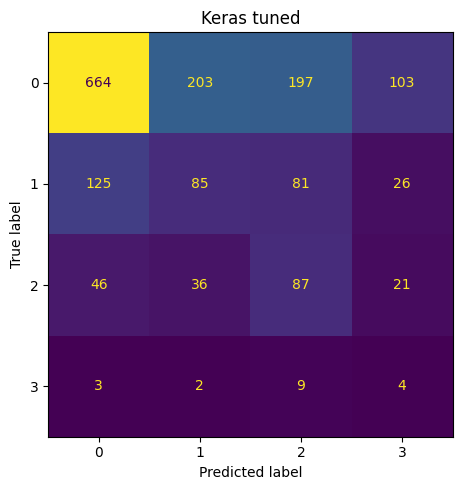

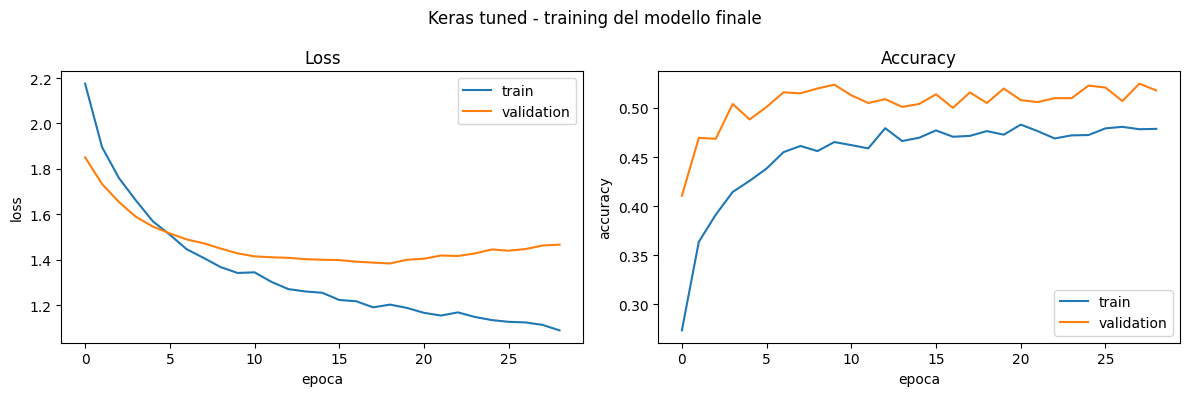

In [29]:
keras_best = rs_keras.best_estimator_
risultati.append(valuta('Keras tuned', keras_best))
plot_confusion(keras_best.predict(X_test), 'Keras tuned')
plot_history(keras_best.named_steps['clf'].history_, 'Keras tuned - training del modello finale')

**Commento.**
- Miglior configurazione: **1 hidden layer da 64 neuroni, ReLU, L2=1e-2, dropout 0.4, learning rate 1e-3, batch 64, class_weight='balanced'**, F1-macro in 5-fold CV **0.311** (deviazione standard 0.013). È la stessa configurazione trovata con la 3-fold: la scelta è robusta rispetto al numero di fold.
- **`class_weight` è il parametro decisivo**: le 8 configurazioni con `balanced` hanno F1-macro media 0.289, le 2 senza 0.231 (e sono le ultime due). Conferma quanto visto nella sezione 6.5.
- Le configurazioni migliori sono **fortemente regolarizzate** (L2 = 1e-2, dropout 0.4) e piccole: coerente con il segnale debole dei dati, con l'overfitting rapidissimo visto in 6.1 e con il confronto fra architetture della sezione 7.
- La griglia allargata (riquadro sopra) ha dato un risultato peggiore: con un budget fisso di configurazioni, uno spazio di ricerca più grande viene esplorato peggio. È un argomento a favore di una griglia mirata, costruita sui risultati degli esperimenti controllati.
- Nel grafico del training finale la validation accuracy è più alta di quella di training: è normale con dropout (attivo solo in training) e con i pesi di classe, che spostano le predizioni verso le classi rare.

Sul test: **F1-macro 0.320, balanced accuracy 0.379**. Recall della classe 2 al 46%, della classe 3 al 22% (4 su 18).

📌 **Report:** tabella `tab_keras_cv`, tabella del confronto `class_weight` None/balanced, iperparametri finali e il risultato della griglia allargata.

## 9. Confronto finale

Tutti i modelli sullo stesso test set. Le colonne sono le stesse degli altri notebook del Modulo 2, così la
tabella si può unire a quelle di Logistic Regression e SVM.

In [30]:
tab_finale = pd.DataFrame(risultati).set_index('modello').sort_values('f1_macro', ascending=False)
tab_finale.round(3)

,accuracy,balanced_acc,f1_macro,roc_auc,f1_0,f1_1,f1_2,f1_3
modello,,,,,,,,
"Keras - rete media (64, 32)",0.504,0.385,0.321,0.665,0.668,0.233,0.316,0.065
Keras tuned,0.496,0.379,0.320,0.674,0.662,0.264,0.309,0.047
"Keras - rete piccola (16,)",0.515,0.347,0.318,0.664,0.684,0.260,0.315,0.013
"Keras - rete grande (256, 128, 64)",0.515,0.359,0.314,0.659,0.677,0.258,0.320,0.000
Keras - cw + batch norm,0.506,0.349,0.312,0.640,0.662,0.285,0.301,0.000
Keras - cw + ReduceLROnPlateau,0.499,0.342,0.304,0.661,0.668,0.230,0.285,0.032
Keras - dropout + class weight,0.499,0.342,0.304,0.661,0.668,0.230,0.285,0.032
Keras - cw + L1 (0.001),0.503,0.341,0.302,0.651,0.672,0.243,0.292,0.000
Perceptron,0.571,0.298,0.294,NaN,0.734,0.195,0.206,0.043


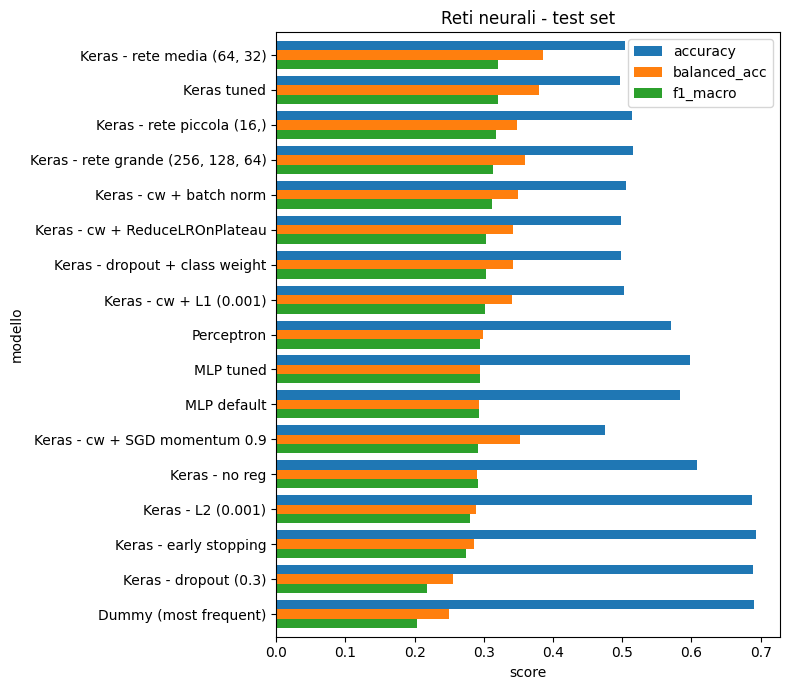

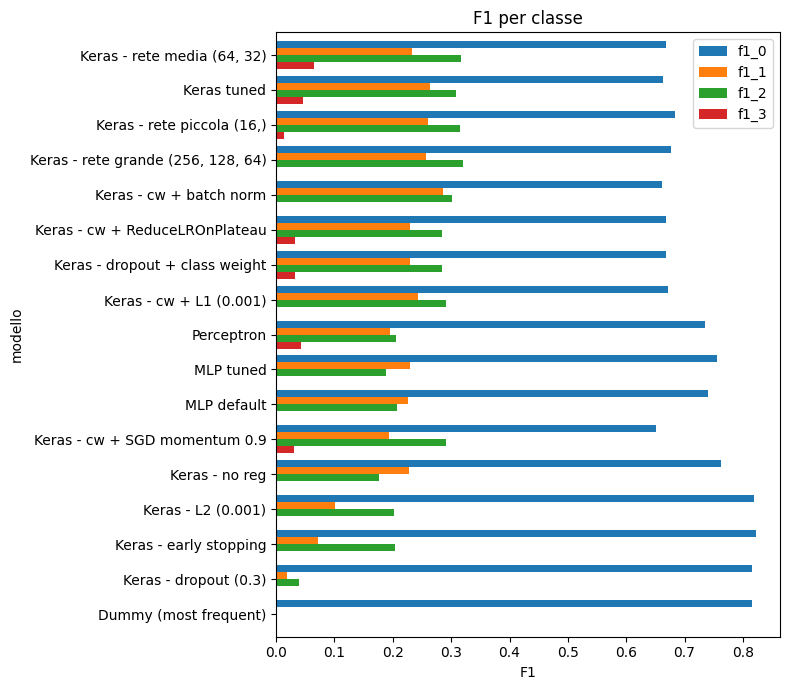

In [31]:
tab_finale[['accuracy', 'balanced_acc', 'f1_macro']].plot(kind='barh', figsize=(8, 7), width=.8)
plt.gca().invert_yaxis(); plt.xlabel('score'); plt.title('Reti neurali - test set')
plt.tight_layout(); plt.show()

f1_cols = [f'f1_{k}' for k in CLASSI]
tab_finale[f1_cols].plot(kind='barh', figsize=(8, 7), width=.8)
plt.gca().invert_yaxis(); plt.xlabel('F1'); plt.title('F1 per classe')
plt.tight_layout(); plt.show()

**Commento.**
- **I modelli migliori sono la rete media (64-32) della sezione 7 (F1-macro 0.321) e la Keras tunata (0.320)**, praticamente alla pari. Come modello finale conviene indicare la **Keras tunata**: è stata scelta con la cross-validation, mentre la rete media è stata scelta guardando il test set, quindi il suo 0.321 è una stima leggermente ottimistica.
- Tutti i modelli con `class_weight` e Adam stanno fra 0.302 e 0.321; tutti quelli **senza** pesi di classe (Perceptron, MLP, Keras no reg) fra 0.29 e 0.30, e quelli regolarizzati senza pesi scendono fino a 0.22. **La gestione dello sbilanciamento conta più dell'architettura e delle tecniche di ottimizzazione.**
- **Accuracy e F1-macro vanno in direzioni opposte**: i modelli con accuracy più alta (~0.69) predicono quasi solo la classe 0, cioè sono quasi il Dummy; i migliori per F1-macro hanno accuracy ~0.50.
- **La classe 3 è la peggiore in tutti i modelli** (F1 ≤ 0.07): solo 70 esempi nel training e 18 nel test, in parte sintetici. Anche quando la rete la predice, la precision resta sotto il 3%.
- La classe 1 ("Mild") è difficile quasi quanto la 2 nonostante abbia più esempi: è una classe "di mezzo", con caratteristiche simili sia alla classe 0 sia alla 2.

📌 **Report:** questa tabella (anche ridotta a Dummy, Perceptron, MLP tuned, Keras no reg, Keras dropout + class weight, rete media, Keras tuned) e il grafico della F1 per classe. Va poi unita alle tabelle di LR e SVM, **dopo che l'SVM sarà stato rieseguito con lo stesso split** (per confronto: la LR finale ha F1-macro ≈ 0.31 sullo stesso test set).

### Curve ROC e Precision-Recall dei due modelli migliori

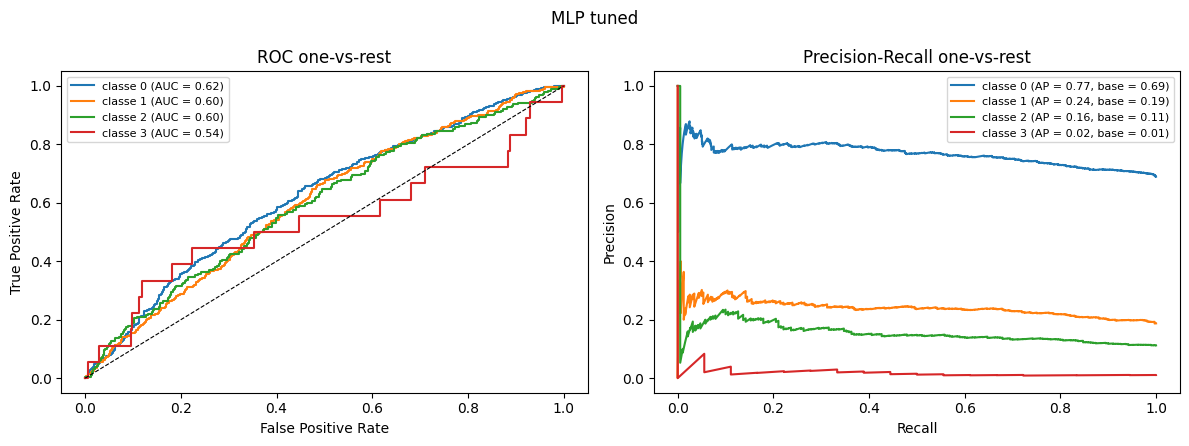

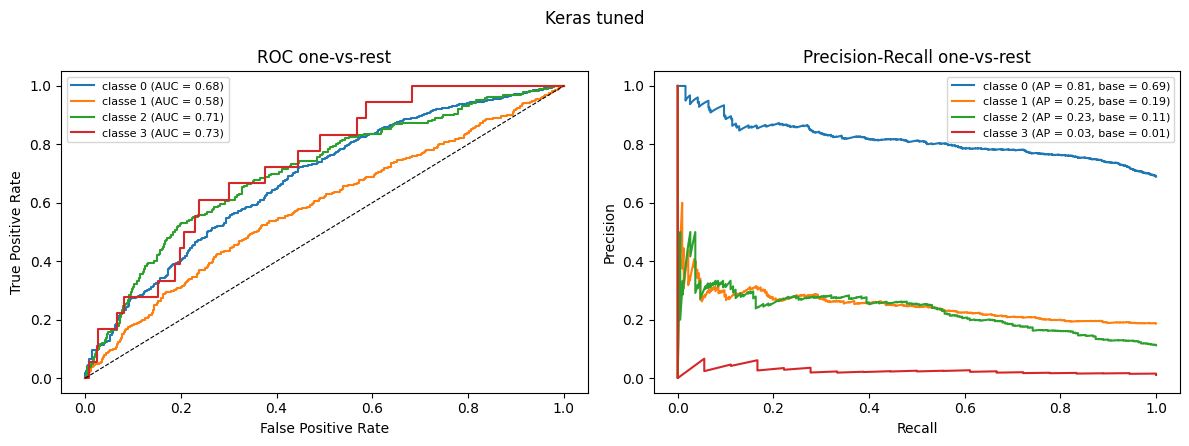

In [32]:
plot_roc_pr(mlp_best.predict_proba(X_test), 'MLP tuned')
plot_roc_pr(keras_best.predict_proba(X_test), 'Keras tuned')

**Commento.**
- **Keras tuned** ha ROC AUC per classe fra 0.58 (classe 1) e 0.73 (classe 3); l'**MLP** fra 0.54 e 0.62. La rete Keras ordina meglio i soggetti, soprattutto per le classi 2 e 3.
- La classe 1 ha l'AUC più bassa nella rete Keras: conferma che è la più difficile da separare dalle altre.
- Le curve **Precision-Recall** vanno lette rispetto alla base, cioè la frequenza della classe (riportata in legenda): per la classe 3 l'AP è 0.03 contro una base di 0.01, quindi meglio del caso ma con una precision bassissima a qualunque soglia. Per la classe 2 l'AP di Keras (0.23) è il doppio della base (0.11).
- L'AUC della classe 3 (0.73) va presa con cautela: è calcolata su 18 esempi positivi, e infatti la curva rossa procede a scalini.

📌 **Report:** le due figure ROC/PR (o solo quella di Keras tuned) + la frase sulla classe 3: AUC discreta ma precision bassissima, quindi il modello non è utilizzabile per individuare i casi gravi.

## 10. Sintesi per il report

**Riepilogo dei risultati da riportare** (numeri del run di riferimento):

| Modello | F1-macro | Bal. acc. | ROC AUC | Accuracy |
|---|---|---|---|---|
| Dummy | 0.204 | 0.250 | 0.500 | 0.690 |
| Perceptron | 0.294 | 0.298 | – | 0.571 |
| MLP tuned (sklearn) | 0.294 | 0.294 | 0.589 | 0.598 |
| Keras no reg | 0.292 | 0.290 | 0.576 | 0.608 |
| Keras dropout + class weight | 0.304 | 0.342 | 0.661 | 0.499 |
| Keras + batch norm | 0.312 | 0.349 | 0.640 | 0.506 |
| Keras rete media (64-32) | 0.321 | 0.385 | 0.665 | 0.504 |
| **Keras tuned** | **0.320** | **0.379** | 0.674 | 0.496 |

**Messaggi chiave per il report**
1. **Overfitting rapidissimo**: senza regolarizzazione la validation loss è minima dopo 3 epoche e poi diverge; la training accuracy arriva al 100%.
2. **Criteri che evitano l'overfitting**: early stopping sulla validation loss con `restore_best_weights`, dropout 0.3-0.4, L2 1e-3/1e-2, reti piccole o medie (la rete grande inizia ad andare in overfitting dopo circa 20 epoche, la piccola è in leggero underfitting).
3. **Evitare l'overfitting non basta**: early stopping, L2 e dropout senza pesi di classe fanno collassare la rete sulla classe 0 (accuracy alta, F1-macro bassa). In sklearn lo stesso succede con `early_stopping=True`, che monitora l'accuracy.
4. **Il class weight è il parametro decisivo** (in CV: 0.289 contro 0.231 di F1-macro media). L'MLP di sklearn non lo supporta, ed è il motivo principale per cui la versione Keras va meglio.
5. **Le tecniche di ottimizzazione aggiuntive non aiutano in modo significativo**: Batch Normalization +0.008 (ma perde la classe 3), L1 e SGD con momentum equivalenti o peggiori, ReduceLROnPlateau non ha effetto (l'early stopping ripristina i pesi prima della riduzione del learning rate). Allargare la griglia di tuning con queste opzioni ha peggiorato il risultato (0.309 contro 0.320).
6. **La capacità del modello conta poco**: reti da 1.172 a 59.076 parametri ottengono la stessa F1-macro (0.314–0.321).
10. **Variabilità fra esecuzioni**: rieseguendo il notebook su un altro computer, le parti scikit-learn danno risultati identici, mentre alcune reti Keras cambiano fino a ±0.01 di F1-macro (es. Batch Normalization 0.307 / 0.312, L2 0.291 / 0.280) per differenze numeriche di hardware e librerie. Il modello finale (Keras tuned, 0.320) e tutte le conclusioni restano invariati. **Differenze inferiori a circa 0.01 fra varianti Keras non vanno quindi interpretate come miglioramenti reali.**
7. **Classe peggiore: la 3** in tutti i modelli (18 esempi nel test, F1 ≤ 0.07).
8. **Accuracy fuorviante**: i modelli con l'accuracy più alta sono i peggiori per F1-macro.
9. **Le reti neurali non superano nettamente i modelli lineari** (Perceptron ≈ MLP; LR ≈ 0.31): il segnale nei dati è debole e in buona parte lineare.

**Grafici da inserire**: curve loss/accuracy della rete senza regolarizzazione (6.1), confronto delle validation loss (6.10), training/validation loss delle tre architetture (7), confusion matrix di Keras tuned, ROC/PR di Keras tuned, F1 per classe (sezione 9).

**Tabelle da inserire**: varianti Keras (6.6–6.9), architetture (7), configurazioni provate per MLP e Keras (prime righe), effetto di `early_stopping` (MLP) e di `class_weight` (Keras), tabella finale.